# ReviewLens — Prompted LLM Sentiment Classification (Quoc Cuong Dinh)

**Method:** Llama 3.1 8B Instruct, prompted with *no* task-specific training.
Zero-shot vs few-shot (examples drawn only from the training split).

**What this notebook does**
1. Shared data prep (only if the team's shared split does not already exist on Drive):
   Cell Phones & Accessories reviews → clean → 100–300 words → star-based labels →
   balanced 50,000 sample → stratified 80/10/10 split, plus 600 extra reviews (200 per star class).
2. Zero-shot and few-shot prompting of Llama 3.1 8B Instruct
   (instruction: "Return only one label: Positive, Neutral, or Negative.").
3. Label extraction: normalised exact match, then case-insensitive whole-word fallback.
4. Evaluation on the shared test set: accuracy, per-class P/R/F1, micro & macro P/R/F1
   (macro-F1 = main metric), plus a separate confusion matrix.
5. AI-assisted labeling of the 600 extra reviews (Claude API, small batches,
   no star ratings shown) — saved to the shared folder for the whole team.
6. Experiment 2: final prompted model vs the AI labels on those 600 reviews.
7. Results tables: per-class metrics for every setting, validation vs test, all confusion matrices.
8. Error analysis (fallback-extracted outputs, misclassified test reviews) and
   inference cost (prompt length, seconds per review).

**Before running (Runtime → Change runtime type → A100 or L4 GPU)**
- Accept the Llama 3.1 license at https://huggingface.co/meta-llama/Llama-3.1-8B-Instruct
- Add Colab secrets (key icon in the left sidebar): `HF_TOKEN` and `ANTHROPIC_API_KEY`.

## 0. Install packages

In [1]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "transformers>=4.56", "accelerate", "huggingface_hub", "orjson", "emoji",
                "anthropic", "scikit-learn", "seaborn"], check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'transformers>=4.56', 'accelerate', 'huggingface_hub', 'orjson', 'emoji', 'anthropic', 'scikit-learn', 'seaborn'], returncode=0)

## 1. Configuration

In [2]:
from pathlib import Path

SEED = 42

# --- Paths (Google Drive so results survive runtime disconnects) ---
DRIVE_ROOT = Path("/content/drive/MyDrive/ReviewLens")
SHARED_DIR = DRIVE_ROOT / "shared_data"        # split shared by all three members
OUT_DIR    = DRIVE_ROOT / "quoc_llama_prompting"  # this member's outputs
FORCE_REBUILD_DATA = False                     # True = rebuild split even if it exists (avoid!)

# --- Data (from the proposal) ---
HF_DATA_REPO = "McAuley-Lab/Amazon-Reviews-2023"
HF_DATA_FILE = "raw/review_categories/Cell_Phones_and_Accessories.jsonl"  # ~9.3 GB
MIN_WORDS, MAX_WORDS = 100, 300
TARGET_PER_CLASS = {"Negative": 16667, "Neutral": 16667, "Positive": 16666}  # = 50,000
EXTRA_PER_CLASS = 200          # 600 extra reviews for AI-assisted labeling (Experiment 2)
RESERVOIR_PER_CLASS = 40000    # uniform random pool per class kept while streaming the file
INCLUDE_TITLE = False          # proposal classifies the review text; set True to prepend title

LABELS = ["Negative", "Neutral", "Positive"]
INVALID = "Invalid"

# --- Llama prompting ---
MODEL_ID = "meta-llama/Llama-3.1-8B-Instruct"
LOAD_IN_4BIT = False           # bf16 fits on A100/L4; True only if memory is tight
MAX_NEW_TOKENS = 8
BATCH_SIZE_ZERO = 32
BATCH_SIZE_FEW = 8
K_PER_CLASS_GRID = [1, 2, 3]   # few-shot sizes tried on validation (3, 6, 9 examples)
FEWSHOT_MAX_WORDS = 150        # keep demonstration reviews short so prompts stay compact
VAL_SUBSAMPLE_PER_CLASS = 200  # validation subset for choosing k; None = full validation set

# --- AI-assisted labeling of the 600 extra reviews (Claude API) ---
AI_PROVIDER = "claude"
CLAUDE_MODEL = "claude-haiku-5-5"   # $0.10 / $0.50 per MTok for prompts up to 100K tokens
AI_MODEL = CLAUDE_MODEL
AI_BATCH_SIZE = 10
AI_SECONDS_BETWEEN_CALLS = 0.5      # paid API: no free-tier daily cap, so no long pauses needed
AI_MAX_RETRIES = 4
AI_MAX_TOKENS = 2048                # Haiku 5.5 counts thinking tokens toward max_tokens
AI_EFFORT = "low"                   # output_config.effort: less thinking for a simple labeling task

# --- Error analysis and inference timing ---
N_ERROR_EXAMPLES = 2                # misclassified test reviews shown per (gold, predicted) pair
TIMING_PER_CLASS = 100              # test reviews per class used to time inference (300 total)


## 2. Setup: Drive, secrets, seeds, GPU

In [3]:
import os, re, json, html, time, random, hashlib
from collections import Counter

import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

from google.colab import drive, userdata
drive.mount("/content/drive")
SHARED_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

HF_TOKEN = userdata.get("HF_TOKEN")
from huggingface_hub import login
login(token=HF_TOKEN)

import transformers, sklearn
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE — switch runtime to GPU")
print(f"torch {torch.__version__} | transformers {transformers.__version__} | "
      f"pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

Mounted at /content/drive
Mounted at /content/drive
GPU: NVIDIA L4
torch 2.11.0+cu130 | transformers 5.22.0 | pandas 2.2.3 | scikit-learn 1.6.1
GPU: NVIDIA L4
torch 2.11.0+cu130 | transformers 5.22.0 | pandas 2.2.3 | scikit-learn 1.6.1


## 3. Shared data preparation
Runs only if `train.csv / val.csv / test.csv / extra_600.csv` are not already in `SHARED_DIR`.
If a teammate already built the split, point `SHARED_DIR` at their folder so all three
methods use the identical data.

Cleaning: remove HTML line breaks, links, @mentions and stray @, `#` symbols, emojis.
The 100–300 word rule is applied to the **cleaned** text, so every final review satisfies it.

In [4]:
import emoji

URL_RE      = re.compile(r"(https?://\S+|www\.\S+)", re.IGNORECASE)
HTML_TAG_RE = re.compile(r"<[^>]+>")
MENTION_RE  = re.compile(r"@\w+")
WS_RE       = re.compile(r"\s+")

def clean_text(t: str) -> str:
    t = html.unescape(t or "")
    t = HTML_TAG_RE.sub(" ", t)          # <br />, <a ...>
    t = URL_RE.sub(" ", t)               # links
    t = MENTION_RE.sub(" ", t)           # mentions
    t = t.replace("@", " ").replace("#", "")  # leftover @ symbols, # symbols (keep the word)
    t = emoji.replace_emoji(t, replace=" ")   # emojis
    return WS_RE.sub(" ", t).strip()

def rating_to_label(r):
    r = int(round(float(r)))
    return "Negative" if r <= 2 else ("Neutral" if r == 3 else "Positive")

def make_review_id(rec) -> str:
    key = f"{rec.get('user_id')}|{rec.get('parent_asin')}|{rec.get('asin')}|{rec.get('timestamp')}"
    return hashlib.md5(key.encode()).hexdigest()[:16]

def build_shared_data():
    import orjson
    from huggingface_hub import hf_hub_download
    from sklearn.model_selection import train_test_split

    path = hf_hub_download(HF_DATA_REPO, HF_DATA_FILE, repo_type="dataset",
                           cache_dir="/content/hf_cache", token=HF_TOKEN)

    rng = random.Random(SEED)
    reservoir = {l: [] for l in LABELS}
    n_seen = Counter()
    seen_hashes = set()
    stats = Counter()

    with open(path, "rb") as f:
        for line in tqdm(f, desc="Scanning reviews", unit=" rev", mininterval=10):
            stats["total"] += 1
            rec = orjson.loads(line)
            text = rec.get("text") or ""
            n_raw = len(text.split())
            if n_raw < 80 or n_raw > 400:          # cheap pre-filter; exact rule applied below
                continue
            cleaned = clean_text(text)
            wc = len(cleaned.split())
            if not (MIN_WORDS <= wc <= MAX_WORDS):
                continue
            stats["in_word_range"] += 1
            h = hashlib.md5(cleaned.lower().encode()).digest()
            if h in seen_hashes:                   # drop duplicate review texts
                stats["duplicates"] += 1
                continue
            seen_hashes.add(h)

            label = rating_to_label(rec["rating"])
            row = {
                "review_id": make_review_id(rec),
                "rating": int(round(float(rec["rating"]))),
                "label": label,
                "text": cleaned,
                "title": clean_text(rec.get("title") or ""),
                "word_count": wc,
                "parent_asin": rec.get("parent_asin"),
            }
            # Reservoir sampling: uniform random sample per class with bounded memory
            n_seen[label] += 1
            res = reservoir[label]
            if len(res) < RESERVOIR_PER_CLASS:
                res.append(row)
            else:
                j = rng.randrange(n_seen[label])
                if j < RESERVOIR_PER_CLASS:
                    res[j] = row

    print("Scan stats:", dict(stats), "| eligible per class:", dict(n_seen))

    main_parts, extra_parts = [], []
    for label in LABELS:
        need = TARGET_PER_CLASS[label] + EXTRA_PER_CLASS
        pool = reservoir[label]
        assert len(pool) >= need, f"Not enough {label} reviews: {len(pool)} < {need}"
        random.Random(SEED).shuffle(pool)
        main_parts.append(pd.DataFrame(pool[:TARGET_PER_CLASS[label]]))
        extra_parts.append(pd.DataFrame(pool[TARGET_PER_CLASS[label]:need]))

    df_main = pd.concat(main_parts, ignore_index=True)
    df_extra = pd.concat(extra_parts, ignore_index=True)
    assert not set(df_main.review_id) & set(df_extra.review_id)

    train, temp = train_test_split(df_main, test_size=0.20, stratify=df_main["label"], random_state=SEED)
    val, test = train_test_split(temp, test_size=0.50, stratify=temp["label"], random_state=SEED)

    for name, d in [("train", train), ("val", val), ("test", test), ("extra_600", df_extra)]:
        d.reset_index(drop=True).to_csv(SHARED_DIR / f"{name}.csv", index=False)

    card = {"seed": SEED, "source": f"{HF_DATA_REPO}/{HF_DATA_FILE}", "word_range": [MIN_WORDS, MAX_WORDS],
            "scan_stats": dict(stats), "eligible_per_class": dict(n_seen),
            "sizes": {"train": len(train), "val": len(val), "test": len(test), "extra": len(df_extra)}}
    (SHARED_DIR / "data_card.json").write_text(json.dumps(card, indent=2))
    print(json.dumps(card, indent=2))

needed = [SHARED_DIR / f"{n}.csv" for n in ("train", "val", "test", "extra_600")]
if FORCE_REBUILD_DATA or not all(p.exists() for p in needed):
    build_shared_data()
else:
    print("Using existing shared split in", SHARED_DIR)

train_df = pd.read_csv(SHARED_DIR / "train.csv")
val_df   = pd.read_csv(SHARED_DIR / "val.csv")
test_df  = pd.read_csv(SHARED_DIR / "test.csv")
extra_df = pd.read_csv(SHARED_DIR / "extra_600.csv")
for name, d in [("train", train_df), ("val", val_df), ("test", test_df), ("extra", extra_df)]:
    print(f"{name:>5}: {len(d):>6}  {d['label'].value_counts().to_dict()}")

def review_input(row) -> str:
    if INCLUDE_TITLE and isinstance(row.get("title"), str) and row["title"]:
        return f"{row['title']}. {row['text']}"
    return row["text"]

Using existing shared split in /content/drive/MyDrive/ReviewLens/shared_data
train:  40000  {'Neutral': 13334, 'Negative': 13333, 'Positive': 13333}
  val:   5000  {'Positive': 1667, 'Negative': 1667, 'Neutral': 1666}
 test:   5000  {'Neutral': 1667, 'Negative': 1667, 'Positive': 1666}
extra:    600  {'Negative': 200, 'Neutral': 200, 'Positive': 200}


## 4. Label extraction rule (shared with the QLoRA method)
1. Normalise: strip whitespace, surrounding quotes/punctuation/markdown, lowercase → exact match.
2. Fallback: case-insensitive whole-word match of positive/neutral/negative (first occurrence).
3. Otherwise `Invalid` (counted as an error).

In [5]:
_LABEL_MAP = {l.lower(): l for l in LABELS}
_WORD_RE = re.compile(r"\b(positive|neutral|negative)\b", re.IGNORECASE)

def extract_label_with_method(raw):
    if not isinstance(raw, str):
        return INVALID, "invalid"
    norm = raw.strip().strip(" \t\r\n\"'`*_.:;,!?()[]{}<>").lower()
    if norm in _LABEL_MAP:
        return _LABEL_MAP[norm], "exact"
    m = _WORD_RE.search(raw)
    if m:
        return _LABEL_MAP[m.group(1).lower()], "fallback"
    return INVALID, "invalid"

def extract_label(raw):
    return extract_label_with_method(raw)[0]

for s, exp in [("Positive", "Positive"), (" negative.", "Negative"), ("**Neutral**", "Neutral"),
               ("Label: Negative", "Negative"), ("The sentiment is positive", "Positive"),
               ("I think so", INVALID), ("Unpositive", INVALID)]:
    assert extract_label(s) == exp, (s, extract_label(s))
print("Extraction rule tests passed.")

Extraction rule tests passed.


## 5. Load Llama 3.1 8B Instruct

In [6]:
from transformers import AutoTokenizer, AutoModelForCausalLM

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, token=HF_TOKEN)
tokenizer.padding_side = "left"                 # required for batched generation
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

load_kwargs = dict(device_map="auto", token=HF_TOKEN, dtype=torch.bfloat16)
if LOAD_IN_4BIT:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "bitsandbytes"], check=True)
    from transformers import BitsAndBytesConfig
    load_kwargs["quantization_config"] = BitsAndBytesConfig(
        load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.bfloat16)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, **load_kwargs)
model.eval()

EOS_IDS = list({tokenizer.eos_token_id, tokenizer.convert_tokens_to_ids("<|eot_id|>")})

config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/55.4k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/184 [00:00<?, ?B/s]

## 6. Prompts
Zero-shot and few-shot use the *same* system message and user instruction; few-shot adds
k training reviews per class as prior user/assistant turns (shuffled class order).

In [7]:
SYSTEM_PROMPT = (
    "You are a sentiment classifier for e-commerce product reviews. "
    "Read the customer review and classify its overall sentiment as Positive, Neutral, or Negative. "
    "Return only one label: Positive, Neutral, or Negative."
)

def user_turn(review_text: str) -> str:
    return (f'Review:\n"""\n{review_text}\n"""\n\n'
            "Return only one label: Positive, Neutral, or Negative.")

def select_fewshot(k_per_class: int, seed: int = SEED):
    """Draw k demonstrations per class from the TRAINING split only."""
    pool = train_df[train_df["word_count"] <= FEWSHOT_MAX_WORDS]
    shots = []
    for label in LABELS:
        shots.append(pool[pool["label"] == label].sample(n=k_per_class, random_state=seed))
    shots = pd.concat(shots).sample(frac=1.0, random_state=seed)   # mix class order
    return [(review_input(r), r["label"]) for _, r in shots.iterrows()]

def build_prompt(review_text: str, shots=None) -> str:
    messages = [{"role": "system", "content": SYSTEM_PROMPT}]
    for ex_text, ex_label in (shots or []):
        messages.append({"role": "user", "content": user_turn(ex_text)})
        messages.append({"role": "assistant", "content": ex_label})
    messages.append({"role": "user", "content": user_turn(review_text)})
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

# Save example prompts for the report
example_text = review_input(test_df.iloc[0])
(OUT_DIR / "prompt_example_zero_shot.txt").write_text(build_prompt(example_text))
(OUT_DIR / "prompt_example_few_shot_k1.txt").write_text(build_prompt(example_text, select_fewshot(1)))
print(build_prompt(example_text)[-600:])

esn't slip out of my hand when i am holding it, and the corner is comfortable to hold to my ear. I have had the current case on for about 2 months and other than the corner chip on the "chrome" from where I dropped it down a flight of concrete stairs it still looks brand new. All the apple and aftermarket charging cords/headphones/docking stations/ etc i have work with the case ON, and I am totally happy with it, even if it were twice the price (shhh don't tell the seller LOL) .
"""

Return only one label: Positive, Neutral, or Negative.<|eot_id|><|start_header_id|>assistant<|end_header_id|>




## 7. Batched greedy inference (resumable)
Raw outputs are appended to a JSONL on Drive, so a disconnect does not lose progress.

In [8]:
@torch.inference_mode()
def generate_batch(prompts):
    enc = tokenizer(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
    out = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                         temperature=None, top_p=None,
                         pad_token_id=tokenizer.pad_token_id, eos_token_id=EOS_IDS)
    return tokenizer.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)

def run_llama(df: pd.DataFrame, tag: str, shots=None, batch_size: int = 16, gold_col: str = "label"):
    raw_path = OUT_DIR / f"raw_{tag}.jsonl"
    done = {}
    if raw_path.exists():
        with open(raw_path) as f:
            for line in f:
                rec = json.loads(line); done[rec["review_id"]] = rec["raw"]
    todo = df[~df["review_id"].isin(done)].reset_index(drop=True)
    if len(todo):
        prompts = [build_prompt(review_input(r), shots) for _, r in todo.iterrows()]
        order = np.argsort([-len(p) for p in prompts])        # longest first: OOM shows up early
        bs, i = batch_size, 0
        pbar = tqdm(total=len(order), desc=tag)
        with open(raw_path, "a") as f:
            while i < len(order):
                idx = order[i:i + bs]
                try:
                    outs = generate_batch([prompts[j] for j in idx])
                except torch.cuda.OutOfMemoryError:
                    torch.cuda.empty_cache(); bs = max(1, bs // 2)
                    print(f"OOM → batch size {bs}"); continue
                for j, o in zip(idx, outs):
                    rid = todo.loc[j, "review_id"]; done[rid] = o
                    f.write(json.dumps({"review_id": rid, "raw": o}) + "\n")
                f.flush(); i += len(idx); pbar.update(len(idx))
        pbar.close()
    res = df[["review_id", gold_col]].copy().rename(columns={gold_col: "gold"})
    res["raw_output"] = res["review_id"].map(done)
    res[["pred", "extract_method"]] = res["raw_output"].apply(lambda s: pd.Series(extract_label_with_method(s)))
    res.to_csv(OUT_DIR / f"preds_{tag}.csv", index=False)
    print(f"{tag}: extraction methods {res['extract_method'].value_counts().to_dict()}")
    return res

## 8. Metrics and confusion matrix

In [9]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, cohen_kappa_score
import matplotlib.pyplot as plt
import seaborn as sns

def compute_metrics(y_true, y_pred, name: str) -> dict:
    y_true, y_pred = list(y_true), list(y_pred)
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, zero_division=0)
    mi = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, average="micro", zero_division=0)
    ma = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, average="macro", zero_division=0)
    m = {"setting": name, "n": len(y_true),
         "accuracy": accuracy_score(y_true, y_pred),
         "macro_precision": ma[0], "macro_recall": ma[1], "macro_f1": ma[2],
         "micro_precision": mi[0], "micro_recall": mi[1], "micro_f1": mi[2],
         "invalid_rate": float(np.mean([y == INVALID for y in y_pred]))}
    for i, l in enumerate(LABELS):
        m[f"{l}_precision"], m[f"{l}_recall"], m[f"{l}_f1"], m[f"{l}_support"] = p[i], r[i], f[i], int(s[i])
    return m

def print_metrics(m: dict):
    print(f"\n=== {m['setting']} (n={m['n']}) ===")
    print(f"Accuracy {m['accuracy']:.4f} | Macro P/R/F1 {m['macro_precision']:.4f}/{m['macro_recall']:.4f}/"
          f"{m['macro_f1']:.4f} | Micro P/R/F1 {m['micro_precision']:.4f}/{m['micro_recall']:.4f}/"
          f"{m['micro_f1']:.4f} | Invalid {m['invalid_rate']:.2%}")
    print(pd.DataFrame({l: [m[f"{l}_precision"], m[f"{l}_recall"], m[f"{l}_f1"], m[f"{l}_support"]]
                        for l in LABELS}, index=["precision", "recall", "f1", "support"]).T.round(4))

def confusion_df(y_true, y_pred, gold_name="Gold") -> pd.DataFrame:
    cols = LABELS + ([INVALID] if INVALID in set(y_pred) else [])
    cm = pd.crosstab(pd.Series(list(y_true), name=gold_name), pd.Series(list(y_pred), name="Predicted"))
    return cm.reindex(index=LABELS, columns=cols, fill_value=0)

def plot_confusion(y_true, y_pred, title: str, fname: str, gold_name="Gold"):
    cm = confusion_df(y_true, y_pred, gold_name)
    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title(title); plt.tight_layout(); plt.savefig(OUT_DIR / fname, dpi=150); plt.show()
    cm.to_csv(OUT_DIR / fname.replace(".png", ".csv"))

ALL_RESULTS = []

## 9. Choose the few-shot size on validation (test set untouched)

In [10]:
if VAL_SUBSAMPLE_PER_CLASS:
    # Same rows as the earlier groupby().apply() version, without the pandas deprecation warning
    val_eval = pd.concat([g.sample(n=VAL_SUBSAMPLE_PER_CLASS, random_state=SEED)
                          for _, g in val_df.groupby("label")], ignore_index=True)
else:
    val_eval = val_df

val_scores = {}
res = run_llama(val_eval, "val_zero_shot", shots=None, batch_size=BATCH_SIZE_ZERO)
val_scores["zero_shot"] = compute_metrics(res["gold"], res["pred"], "val zero-shot")
for k in K_PER_CLASS_GRID:
    res = run_llama(val_eval, f"val_few_shot_k{k}", shots=select_fewshot(k), batch_size=BATCH_SIZE_FEW)
    val_scores[f"few_shot_k{k}"] = compute_metrics(res["gold"], res["pred"], f"val few-shot k={k}/class")

val_table = pd.DataFrame(val_scores.values())[["setting", "accuracy", "macro_f1", "invalid_rate"]]
print(val_table.round(4))
val_table.to_csv(OUT_DIR / "validation_selection.csv", index=False)

few_keys = [f"few_shot_k{k}" for k in K_PER_CLASS_GRID]
BEST_K = K_PER_CLASS_GRID[int(np.argmax([val_scores[key]["macro_f1"] for key in few_keys]))]
FINAL_SETTING = ("few_shot" if val_scores[f"few_shot_k{BEST_K}"]["macro_f1"] >= val_scores["zero_shot"]["macro_f1"]
                 else "zero_shot")
print(f"Best few-shot k = {BEST_K} per class ({3 * BEST_K} examples). Final setting by val macro-F1: {FINAL_SETTING}")

val_zero_shot: extraction methods {'exact': 535, 'fallback': 65}
val_few_shot_k1: extraction methods {'exact': 598, 'fallback': 2}
val_few_shot_k2: extraction methods {'exact': 599, 'fallback': 1}
val_few_shot_k3: extraction methods {'exact': 600}
                  setting  accuracy  macro_f1  invalid_rate
0           val zero-shot    0.6967    0.6800           0.0
1  val few-shot k=1/class    0.7633    0.7611           0.0
2  val few-shot k=2/class    0.7633    0.7554           0.0
3  val few-shot k=3/class    0.7800    0.7767           0.0
Best few-shot k = 3 per class (9 examples). Final setting by val macro-F1: few_shot


## 10. Experiment 1 — test set: zero-shot vs few-shot

test_zero_shot: extraction methods {'exact': 4482, 'fallback': 518}

=== Test — zero-shot (n=5000) ===
Accuracy 0.6986 | Macro P/R/F1 0.7210/0.6986/0.6766 | Micro P/R/F1 0.6986/0.6986/0.6986 | Invalid 0.00%
          precision  recall      f1  support
Negative     0.5918  0.9592  0.7320   1667.0
Neutral      0.6406  0.3239  0.4303   1667.0
Positive     0.9306  0.8127  0.8677   1666.0


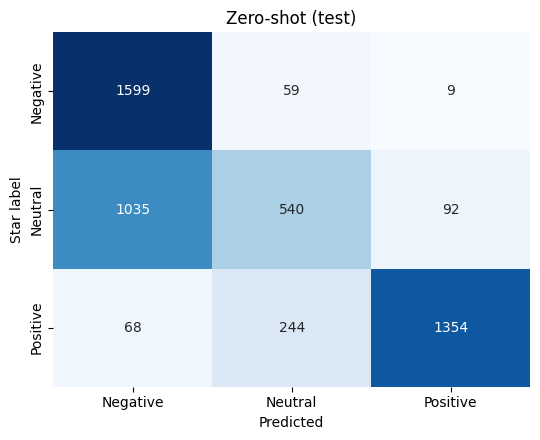

test_few_shot_k3: extraction methods {'exact': 5000}

=== Test — few-shot (k=3/class) (n=5000) ===
Accuracy 0.7622 | Macro P/R/F1 0.7688/0.7622/0.7569 | Micro P/R/F1 0.7622/0.7622/0.7622 | Invalid 0.00%
          precision  recall      f1  support
Negative     0.6890  0.8998  0.7804   1667.0
Neutral      0.7005  0.5387  0.6090   1667.0
Positive     0.9169  0.8481  0.8812   1666.0


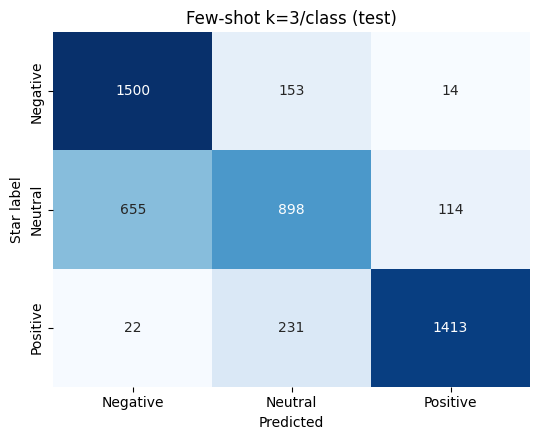

In [11]:
FEW_SHOTS = select_fewshot(BEST_K)
pd.DataFrame(FEW_SHOTS, columns=["text", "label"]).to_csv(OUT_DIR / "few_shot_examples_used.csv", index=False)

test_zero = run_llama(test_df, "test_zero_shot", shots=None, batch_size=BATCH_SIZE_ZERO)
m_zero = compute_metrics(test_zero["gold"], test_zero["pred"], "Test — zero-shot")
print_metrics(m_zero); ALL_RESULTS.append(m_zero)
plot_confusion(test_zero["gold"], test_zero["pred"], "Zero-shot (test)", "cm_test_zero_shot.png", "Star label")

test_few = run_llama(test_df, f"test_few_shot_k{BEST_K}", shots=FEW_SHOTS, batch_size=BATCH_SIZE_FEW)
m_few = compute_metrics(test_few["gold"], test_few["pred"], f"Test — few-shot (k={BEST_K}/class)")
print_metrics(m_few); ALL_RESULTS.append(m_few)
plot_confusion(test_few["gold"], test_few["pred"], f"Few-shot k={BEST_K}/class (test)",
               "cm_test_few_shot.png", "Star label")

## 11. AI-assisted labeling of the 600 extra reviews
Reviews are shuffled (so batches mix classes) and sent in small batches **without star
ratings**. The AI's label distribution may be unequal. Results are saved to the shared
folder so all members evaluate on the same AI labels.

Loaded existing AI labels: /content/drive/MyDrive/ReviewLens/shared_data/ai_labeled_600.csv
AI label distribution: {'Negative': 260, 'Positive': 171, 'Neutral': 169}

=== AI labels vs star labels (n=600) ===
Accuracy 0.7483 | Macro P/R/F1 0.7584/0.7483/0.7457 | Micro P/R/F1 0.7483/0.7483/0.7483 | Invalid 0.00%
          precision  recall      f1  support
Negative     0.6885   0.895  0.7783    200.0
Neutral      0.6568   0.555  0.6016    200.0
Positive     0.9298   0.795  0.8571    200.0
Cohen's kappa (AI vs stars): 0.6225


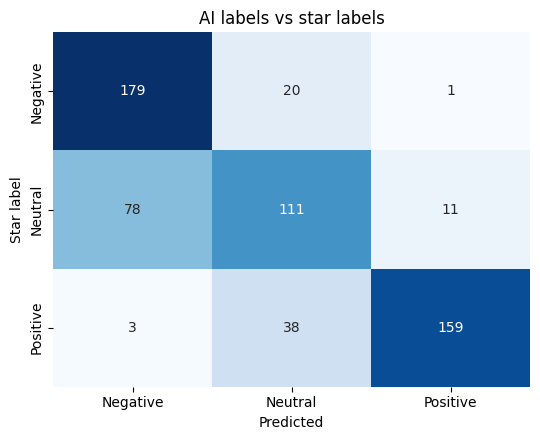

In [12]:
AI_SYSTEM = (
    "You are annotating customer reviews of cell phones and accessories sold online. "
    "For each review, judge the overall sentiment the customer expresses about the product or purchase:\n"
    "- Positive: mainly satisfied or recommending\n"
    "- Neutral: mixed, lukewarm, or balanced between good and bad\n"
    "- Negative: mainly dissatisfied, complaining, or warning others\n"
    "Respond with only a JSON array, one object per review, in the form "
    '[{"id": 1, "label": "Positive"}, ...], using exactly the given ids and only the labels '
    "Positive, Neutral, or Negative. No other text."
)

def ai_user_message(items):
    return "\n\n".join(f"Review id {i}:\n\"\"\"\n{t}\n\"\"\"" for i, t in items)

import anthropic

ai_client = anthropic.Anthropic(api_key=userdata.get("ANTHROPIC_API_KEY"), max_retries=5)


class AIRefusal(Exception):
    """Haiku 5.5 safety classifiers can decline a request (stop_reason == "refusal")."""


def call_ai(msg):
    # Haiku 5.5: no temperature / top_p / top_k, no assistant prefill (both rejected or ignored).
    # output_config goes through extra_body so it works even on older SDK versions.
    resp = ai_client.messages.create(
        model=CLAUDE_MODEL,
        max_tokens=AI_MAX_TOKENS,
        system=AI_SYSTEM,
        messages=[{"role": "user", "content": msg}],
        extra_body={"output_config": {"effort": AI_EFFORT}},
    )
    if resp.stop_reason == "refusal":
        raise AIRefusal("request declined by Haiku 5.5 safety classifier")
    return "".join(b.text for b in resp.content if b.type == "text")


def parse_ai_response(text, n):
    m = re.search(r"\[.*\]", text or "", re.DOTALL)
    if not m:
        return {}
    try:
        arr = json.loads(m.group(0))
    except json.JSONDecodeError:
        return {}
    out = {}
    for obj in arr:
        try:
            i = int(obj["id"]); lab = extract_label(str(obj["label"]))
        except (KeyError, TypeError, ValueError):
            continue
        if 1 <= i <= n and lab != INVALID:
            out[i] = lab
    return out

def ai_label_batch(texts):
    """Label a small batch. If items are missing (parse error, refusal, max_tokens), retry
    them one review at a time so a single problem review cannot block the rest."""
    labels = [None] * len(texts)
    refused = set()
    pending = list(range(len(texts)))
    for attempt in range(AI_MAX_RETRIES):
        if not pending:
            break
        groups = [pending] if attempt == 0 else [[i] for i in pending if i not in refused]
        for grp in groups:
            items = [(n + 1, texts[idx]) for n, idx in enumerate(grp)]
            try:
                parsed = parse_ai_response(call_ai(ai_user_message(items)), len(items))
            except AIRefusal as e:
                print(f"  refusal ({len(grp)} review(s)): {e}")
                parsed = {}
                if len(grp) == 1:
                    refused.add(grp[0])
            except Exception as e:
                print(f"  API error ({type(e).__name__}): {e}")
                parsed = {}
                time.sleep(min(30, 2 * 2 ** attempt))
            for n, idx in enumerate(grp):
                if (n + 1) in parsed:
                    labels[idx] = parsed[n + 1]
        pending = [idx for idx in pending if labels[idx] is None and idx not in refused]
        if pending:
            time.sleep(min(30, 2 * 2 ** attempt))
    return [l if l is not None else INVALID for l in labels]


AI_LABELS_PATH = SHARED_DIR / "ai_labeled_600.csv"
AI_RAW_PATH = OUT_DIR / f"ai_labels_progress_{AI_MODEL}.jsonl"

if AI_LABELS_PATH.exists():
    ai_df = pd.read_csv(AI_LABELS_PATH)
    print("Loaded existing AI labels:", AI_LABELS_PATH)
else:
    done = {}
    if AI_RAW_PATH.exists():
        for line in open(AI_RAW_PATH):
            rec = json.loads(line); done[rec["review_id"]] = rec["ai_label"]
    shuffled = extra_df.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
    todo = shuffled[~shuffled["review_id"].isin(done)].reset_index(drop=True)
    with open(AI_RAW_PATH, "a") as f:
        for start in tqdm(range(0, len(todo), AI_BATCH_SIZE), desc=f"AI labeling ({AI_MODEL})"):
            chunk = todo.iloc[start:start + AI_BATCH_SIZE]
            labs = ai_label_batch([review_input(r) for _, r in chunk.iterrows()])
            for rid, lab in zip(chunk["review_id"], labs):
                done[rid] = lab; f.write(json.dumps({"review_id": rid, "ai_label": lab}) + "\n")
            f.flush(); time.sleep(AI_SECONDS_BETWEEN_CALLS)
    ai_df = shuffled.rename(columns={"label": "star_label"})
    ai_df["ai_label"] = ai_df["review_id"].map(done)
    ai_df["ai_provider"], ai_df["ai_model"] = AI_PROVIDER, AI_MODEL
    n_bad = (ai_df["ai_label"] == INVALID).sum()
    if n_bad:
        print(f"WARNING: {n_bad} reviews could not be labeled; rerun this cell to retry them.")
        AI_RAW_PATH.write_text("".join(json.dumps({"review_id": r, "ai_label": l}) + "\n"
                                       for r, l in done.items() if l != INVALID))
    else:
        ai_df.to_csv(AI_LABELS_PATH, index=False)
        print("Saved shared AI labels →", AI_LABELS_PATH)

print("AI label distribution:", ai_df["ai_label"].value_counts().to_dict())
valid_ai = ai_df[ai_df["ai_label"].isin(LABELS)]
agree = compute_metrics(valid_ai["star_label"], valid_ai["ai_label"], "AI labels vs star labels")
agree["cohen_kappa"] = cohen_kappa_score(valid_ai["star_label"], valid_ai["ai_label"], labels=LABELS)
print_metrics(agree); print(f"Cohen's kappa (AI vs stars): {agree['cohen_kappa']:.4f}")
plot_confusion(valid_ai["star_label"], valid_ai["ai_label"], "AI labels vs star labels",
               "cm_ai_vs_stars.png", "Star label")

## 12. Experiment 2 — final prompted model on the 600 AI-labeled reviews

exp2_few_shot_k3: extraction methods {'exact': 600}

=== Exp2 — few_shot vs AI labels (n=600) ===
Accuracy 0.8817 | Macro P/R/F1 0.8734/0.8766/0.8740 | Micro P/R/F1 0.8817/0.8817/0.8817 | Invalid 0.00%
          precision  recall      f1  support
Negative     0.9183  0.9077  0.9130    260.0
Neutral      0.8141  0.7515  0.7815    169.0
Positive     0.8877  0.9708  0.9274    171.0


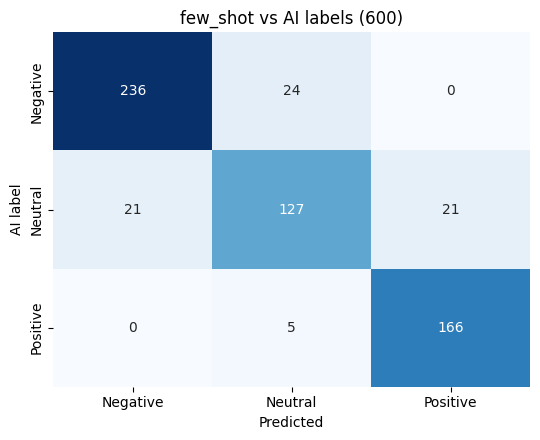


=== Exp2 — few_shot vs star labels (same 600) (n=600) ===
Accuracy 0.7717 | Macro P/R/F1 0.7763/0.7717/0.7662 | Micro P/R/F1 0.7717/0.7717/0.7717 | Invalid 0.00%
          precision  recall      f1  support
Negative     0.7082   0.910  0.7965    200.0
Neutral      0.7115   0.555  0.6236    200.0
Positive     0.9091   0.850  0.8786    200.0


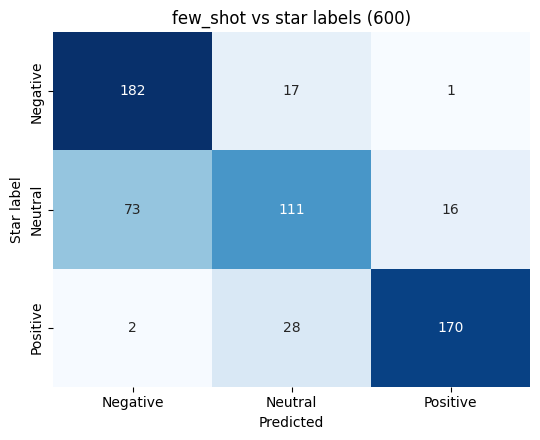

In [13]:
exp2_df = valid_ai.rename(columns={"ai_label": "label"})   # gold = AI label
final_shots = FEW_SHOTS if FINAL_SETTING == "few_shot" else None
final_tag = f"exp2_{FINAL_SETTING}" + (f"_k{BEST_K}" if FINAL_SETTING == "few_shot" else "")
exp2 = run_llama(exp2_df, final_tag, shots=final_shots,
                 batch_size=BATCH_SIZE_FEW if final_shots else BATCH_SIZE_ZERO)

m_exp2_ai = compute_metrics(exp2["gold"], exp2["pred"], f"Exp2 — {FINAL_SETTING} vs AI labels")
print_metrics(m_exp2_ai); ALL_RESULTS.append(m_exp2_ai)
plot_confusion(exp2["gold"], exp2["pred"], f"{FINAL_SETTING} vs AI labels (600)",
               "cm_exp2_vs_ai.png", "AI label")

star_gold = exp2["review_id"].map(dict(zip(ai_df["review_id"], ai_df["star_label"])))
m_exp2_star = compute_metrics(star_gold, exp2["pred"], f"Exp2 — {FINAL_SETTING} vs star labels (same 600)")
print_metrics(m_exp2_star); ALL_RESULTS.append(m_exp2_star)
plot_confusion(star_gold, exp2["pred"], f"{FINAL_SETTING} vs star labels (600)",
               "cm_exp2_vs_stars.png", "Star label")

## 13. Results tables
Per-class precision / recall / F1 for every setting (the AI-vs-star agreement from §11 is
included as a reference row), validation vs test, and all confusion matrices in one figure.

In [14]:
rows = ALL_RESULTS + [agree]
per_class = pd.DataFrame(
    {(l, k): [m[f"{l}_{k}"] for m in rows] for l in LABELS for k in ("precision", "recall", "f1")},
    index=pd.Index([m["setting"] for m in rows], name="setting"))
per_class[("Macro", "f1")] = [m["macro_f1"] for m in rows]
display(per_class.round(4))
per_class.to_csv(OUT_DIR / "per_class_metrics.csv")

best_key = f"few_shot_k{BEST_K}"
val_vs_test = pd.DataFrame([
    {"setting": "zero-shot",
     "val_accuracy": val_scores["zero_shot"]["accuracy"], "val_macro_f1": val_scores["zero_shot"]["macro_f1"],
     "test_accuracy": m_zero["accuracy"], "test_macro_f1": m_zero["macro_f1"]},
    {"setting": f"few-shot k={BEST_K}/class",
     "val_accuracy": val_scores[best_key]["accuracy"], "val_macro_f1": val_scores[best_key]["macro_f1"],
     "test_accuracy": m_few["accuracy"], "test_macro_f1": m_few["macro_f1"]},
])
print(f"Validation subset n={len(val_eval)} | test n={len(test_df)}")
display(val_vs_test.round(4))
val_vs_test.to_csv(OUT_DIR / "val_vs_test.csv", index=False)


Negative                   Neutral  \
                                          precision  recall      f1 precision   
setting                                                                         
Test — zero-shot                             0.5918  0.9592  0.7320    0.6406   
Test — few-shot (k=3/class)                  0.6890  0.8998  0.7804    0.7005   
Exp2 — few_shot vs AI labels                 0.9183  0.9077  0.9130    0.8141   
Exp2 — few_shot vs star labels (same 600)    0.7082  0.9100  0.7965    0.7115   
AI labels vs star labels                     0.6885  0.8950  0.7783    0.6568   

                                                           Positive          \
                                           recall      f1 precision  recall   
setting                                                                       
Test — zero-shot                           0.3239  0.4303    0.9306  0.8127   
Test — few-shot (k=3/class)                0.5387  0.6090    0.9169  0.8481   
Exp2 — few_shot vs AI labels               0.7515  0.7815    0.8877  0.9708   
Exp2 — few_shot vs star labels (same 600)  0.5550  0.6236    0.9091  0.8500   
AI labels vs star labels                   0.5550  0.6016    0.9298  0.7950   

                                                    Macro  
                                               f1      f1  
setting                                                    
Test — zero-shot                           0.8677  0.6766  
Test — few-shot (k=3/class)                0.8812  0.7569  
Exp2 — few_shot vs AI labels               0.9274  0.8740  
Exp2 — few_shot vs star labels (same 600)  0.8786  0.7662  
AI labels vs star labels                   0.8571  0.7457

Validation subset n=600 | test n=5000


,setting,val_accuracy,val_macro_f1,test_accuracy,test_macro_f1
0,zero-shot,0.6967,0.6800,0.6986,0.6766
1,few-shot k=3/class,0.7800,0.7767,0.7622,0.7569


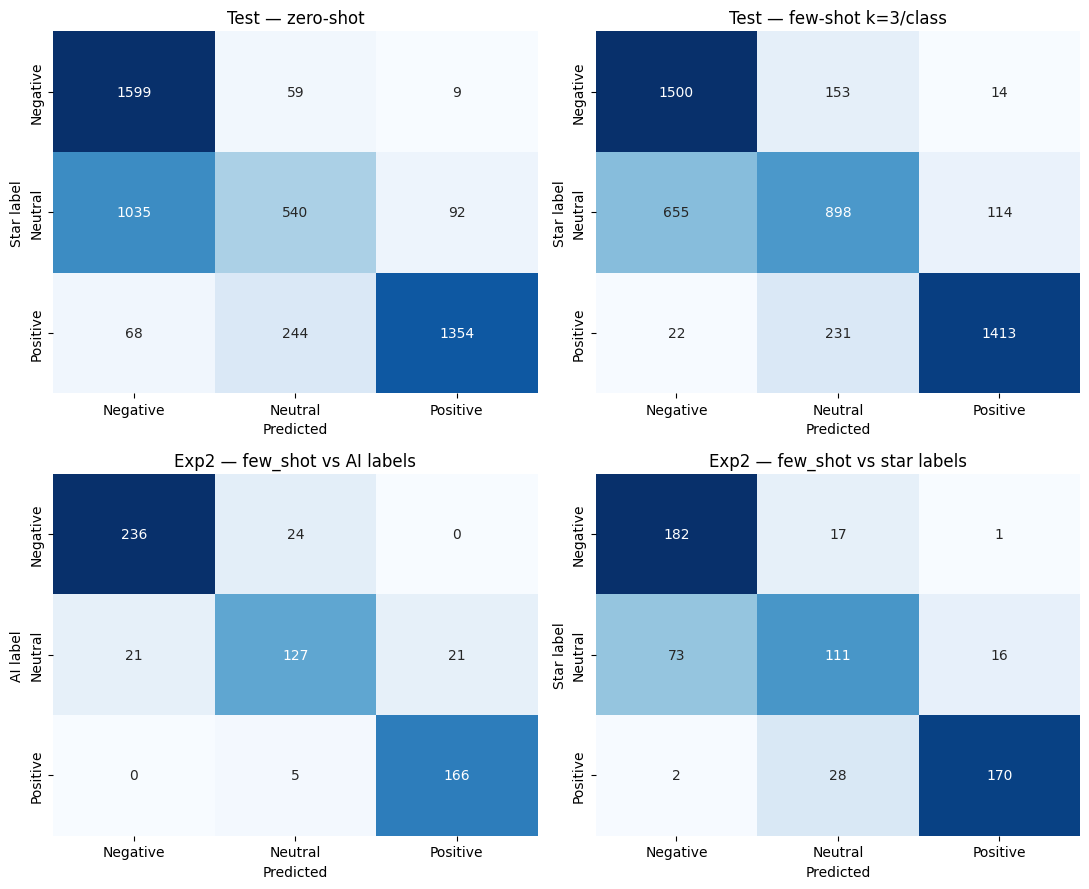

In [15]:
panels = [
    (test_zero["gold"], test_zero["pred"], "Test — zero-shot", "Star label"),
    (test_few["gold"], test_few["pred"], f"Test — few-shot k={BEST_K}/class", "Star label"),
    (exp2["gold"], exp2["pred"], f"Exp2 — {FINAL_SETTING} vs AI labels", "AI label"),
    (star_gold, exp2["pred"], f"Exp2 — {FINAL_SETTING} vs star labels", "Star label"),
]
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (yt, yp, title, gname) in zip(axes.ravel(), panels):
    sns.heatmap(confusion_df(yt, yp, gname), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(title)
plt.tight_layout(); plt.savefig(OUT_DIR / "cm_all_settings.png", dpi=150); plt.show()


## 14. Error analysis
### 14.1 Label extraction: which outputs needed the fallback rule?
Counts of exact vs fallback extraction per setting, then the raw zero-shot outputs that were
not a bare label. Outputs containing more than one label word would make the
first-occurrence fallback ambiguous, so they are counted separately.

In [16]:
extract_table = (pd.DataFrame({
        "test zero-shot": test_zero["extract_method"].value_counts(),
        f"test few-shot k={BEST_K}": test_few["extract_method"].value_counts(),
        f"exp2 {FINAL_SETTING}": exp2["extract_method"].value_counts()})
    .reindex(["exact", "fallback", "invalid"]).fillna(0).astype(int).T)
display(extract_table)
extract_table.to_csv(OUT_DIR / "extraction_methods.csv")

def label_words(s):
    return sorted({w.lower() for w in _WORD_RE.findall(s or "")})

fb = test_zero[test_zero["extract_method"] == "fallback"].copy()
fb["label_words_found"] = fb["raw_output"].apply(lambda s: ", ".join(label_words(s)))
exact_rows = test_zero[test_zero["extract_method"] == "exact"]
print(f"Zero-shot test outputs that needed the fallback rule: {len(fb)} of {len(test_zero)}")
print(f"  containing more than one label word: {fb['label_words_found'].str.contains(',').sum()}")
print(f"  accuracy on fallback rows {(fb['pred'] == fb['gold']).mean():.4f} | "
      f"on exact rows {(exact_rows['pred'] == exact_rows['gold']).mean():.4f}")
display(fb["raw_output"].str.strip().value_counts().head(15).rename_axis("raw output").to_frame("count"))
fb.to_csv(OUT_DIR / "fallback_outputs_test_zero_shot.csv", index=False)


extract_method,exact,fallback,invalid
test zero-shot,4482,518,0
test few-shot k=3,5000,0,0
exp2 few_shot,600,0,0


Zero-shot test outputs that needed the fallback rule: 518 of 5000
  containing more than one label word: 430
  accuracy on fallback rows 0.6293 | on exact rows 0.7066


,count
raw output,
Neutral\n\nThe review mentions both positive and,300
Neutral\n\nThe review mentions both positive aspects,36
Neutral\n\nThe customer has mixed feelings about,16
Neutral\n\nThe review starts with a positive,13
Neutral\n\nThe review mentions several positive aspects,11
Negative\n\nThe customer mentions several negative aspects,9
Neutral\n\nThe customer is generally satisfied with,8
Neutral\n\nThe customer mentions both positive and,8
Neutral\n\nThe review starts with a negative,8


### 14.2 Misclassified test reviews (final setting)
Error counts by (gold, predicted) pair, predictions by star rating (each sentiment label
groups 1–2, 3 and 4–5 stars), and a few example reviews for each error pair.
All misclassified reviews are saved to CSV.

In [17]:
final_test = test_few if FINAL_SETTING == "few_shot" else test_zero
final_name = f"few-shot k={BEST_K}/class" if FINAL_SETTING == "few_shot" else "zero-shot"
ft = final_test.merge(test_df[["review_id", "rating", "text"]], on="review_id")

print(f"Predictions by star rating — test, {final_name}")
display(pd.crosstab(ft["rating"], ft["pred"], margins=True, margins_name="Total"))

err = ft[ft["pred"] != ft["gold"]]
pairs = err.groupby(["gold", "pred"]).size().sort_values(ascending=False).rename("count")
print(f"Errors: {len(err)} of {len(ft)}")
display(pairs.to_frame())
err.to_csv(OUT_DIR / f"misclassified_test_{FINAL_SETTING}.csv", index=False)

examples = pd.concat([err[(err["gold"] == g) & (err["pred"] == p)]
                      .sample(n=min(N_ERROR_EXAMPLES, c), random_state=SEED)
                      for (g, p), c in pairs.items()])
examples["text"] = examples["text"].apply(lambda t: t if len(t) <= 400 else t[:400] + " …")
with pd.option_context("display.max_colwidth", None):
    display(examples[["gold", "pred", "rating", "text"]].reset_index(drop=True))


Predictions by star rating — test, few-shot k=3/class


pred,Negative,Neutral,Positive,Total
rating,,,,
1,904,36,9,949
2,596,117,5,718
3,655,898,114,1667
4,14,190,269,473
5,8,41,1144,1193
Total,2177,1282,1541,5000


Errors: 1189 of 5000


,,count
gold,pred,
Neutral,Negative,655
Positive,Neutral,231
Negative,Neutral,153
Neutral,Positive,114
Positive,Negative,22
Negative,Positive,14


,gold,pred,rating,text
0,Neutral,Negative,3,Let's get put the way that it's cute and it's Hello Kitty so even more cute. As for a phone holder it's ok 3 stars at best. The clamps on the sides of the holder that keep your phone in place is not big enough if you have a pop socket or ring on thr back of your phone. If you have a bulky case this to will not hold your phone. I have to take my case off in order to place my phone in the holder. An …
1,Neutral,Negative,3,"These are great if you don’t plan to “actually use” the phone under water. The case is completely waterproof (which blew my mind), but whenever I tried to press on the camera or anything else, it didn’t work. I was snorkeling off Ocean Reef, and wanted to make a video or at least take photos of what I found under water... But, it appears the plastic phone case is simply too thick. (It works fine u …"
2,Positive,Neutral,4,Bought it for my new S22+. The kickstand was great. Worked for portrait and landscape views and allowed for precise positioning in landscape. Translucent back is nice if you want to show some color. I did like the slimmer profile. Side buttons were east to find/press. A minor annoyance is that it does not lay flat on its back. There is some wobble due to the height difference of the camera and kic …
3,Positive,Neutral,4,"To be honest, I should give this product 5 stars, and someday I may. I bought this because I generally really like Anker products- a quick review of my Amazon orders shows 33 orders with Anker products, and 10 of them are chargers. But this is to replace one of those Anker chargers that is failing. The problem with the failing device is the folding power prongs. The only time I touch the failing c …"
4,Negative,Neutral,2,"I wanted to save the expense of buying a new phone, plus I really liked my 4 year old I phone 7, so I decided to replace the battery. Installation procedure was explained well, but it took me about 6 hours. I am 72, well educated, but my fingers are not nimble and the parts are small and fragile. The screws are super small and I needed a dish to keep them from getting lost and I needed a magnifier …"
5,Negative,Neutral,2,"Just purchased this to try in my 2003 Tundra with a Pioneer Avic700 head unit. Bottom line - the device fits into the cd slot but has absolutely zero holding-strength. It readily, and with almost no force, pulls directly out of the cd slot, and it utterly useless in my particular application. I'm giving this device 2-stars, because it is certainly possibly that my configuration just won't work wit …"
6,Neutral,Positive,3,"I very seldom write reviews - bad habit, as I never buy anything without reading at least 10 reviews BUT this screen protector is absolutely amazing. It actually IMPROVED my screen responsiveness! My phone is new and there was a 'dead' area on the screen that wouldn't respond to the S Pen, finger touch only. After installing this protector my screen response is better than new. It went on fairly e …"
7,Neutral,Positive,3,"I didn't give the product the 5 stars it likely deserves as the first one they sent to me the magnetic latch for the front cover of the phone wouldn't ""stick."" Point of fact, I took small pieces of metal and nothing stuck to the mag that's in the back half of the unit. I returned and received another and it's perfect. Stylish, protective for the entire phone, ease of access to all controls and the …"
8,Positive,Negative,4,"These fit pretty well. They seal water out nicely, but leave just a slight bit along one edge as an air bubble. I have found no other brand that fit or protects even close to these. That said I do a lot around the house and in the shop and garage , and the first one of these I cracked after I hit it on the sharp exposed point of a screw. My bad. Second one lasted about 6 months, but had three chip …"
9,Positive,Negative,4,I have had the blackberry passport for about 3-1/2 weeks. I Decided to give Blackberry a try coming from a iPhone 4s and t

## 15. Inference cost: prompt length and time per review
Prompted Llama needs no training, so its cost is inference only. Prompt lengths are
measured on the full test set with the tokenizer. Time is measured by re-running
generation on a stratified subset of the test set (`TIMING_PER_CLASS` per class, same batch
sizes as the real runs, one untimed warm-up batch). These outputs are only timed, not saved.

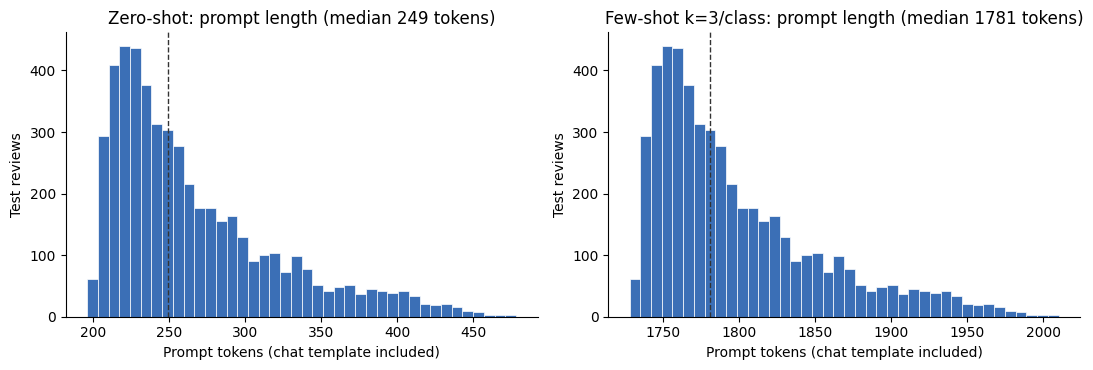

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


GPU: NVIDIA L4 | precision: bf16


,setting,batch_size,prompt_tokens_mean,prompt_tokens_median,prompt_tokens_max,timed_reviews,sec_per_review,reviews_per_sec,est_minutes_full_test,training_time
0,zero-shot,32,266.399,249.0,478,300,0.160,6.263,13.305,0.0
1,few-shot k=3/class,8,1798.399,1781.0,2010,300,0.708,1.412,59.020,0.0


In [18]:
def build_prompts(df, shots):
    return [build_prompt(review_input(r), shots) for _, r in df.iterrows()]

def prompt_lengths(df, shots):
    ids = tokenizer(build_prompts(df, shots), add_special_tokens=False)["input_ids"]
    return np.array([len(x) for x in ids])

def time_inference(df, shots, batch_size):
    prompts = build_prompts(df, shots)
    generate_batch(prompts[:batch_size])                      # warm-up, not timed
    torch.cuda.synchronize(); t0 = time.perf_counter()
    for i in range(0, len(prompts), batch_size):
        generate_batch(prompts[i:i + batch_size])
    torch.cuda.synchronize()
    return time.perf_counter() - t0

len_zero = prompt_lengths(test_df, None)
len_few = prompt_lengths(test_df, FEW_SHOTS)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, lens, title in [(axes[0], len_zero, "Zero-shot"), (axes[1], len_few, f"Few-shot k={BEST_K}/class")]:
    ax.hist(lens, bins=40, color="#3B6FB6", edgecolor="white", linewidth=0.5)
    ax.axvline(np.median(lens), color="#333333", linestyle="--", linewidth=1)
    ax.set_title(f"{title}: prompt length (median {np.median(lens):.0f} tokens)")
    ax.set_xlabel("Prompt tokens (chat template included)"); ax.set_ylabel("Test reviews")
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(OUT_DIR / "prompt_length_hist.png", dpi=150); plt.show()

timing_df = pd.concat([g.sample(n=TIMING_PER_CLASS, random_state=SEED)
                       for _, g in test_df.groupby("label")], ignore_index=True)
cost_rows = []
for name, shots, bs, lens in [("zero-shot", None, BATCH_SIZE_ZERO, len_zero),
                              (f"few-shot k={BEST_K}/class", FEW_SHOTS, BATCH_SIZE_FEW, len_few)]:
    secs = time_inference(timing_df, shots, bs)
    cost_rows.append({
        "setting": name, "batch_size": bs,
        "prompt_tokens_mean": lens.mean(), "prompt_tokens_median": float(np.median(lens)),
        "prompt_tokens_max": int(lens.max()),
        "timed_reviews": len(timing_df), "sec_per_review": secs / len(timing_df),
        "reviews_per_sec": len(timing_df) / secs,
        "est_minutes_full_test": secs / len(timing_df) * len(test_df) / 60,
        "training_time": 0.0})
cost = pd.DataFrame(cost_rows)
print("GPU:", torch.cuda.get_device_name(0), "| precision:", "4-bit" if LOAD_IN_4BIT else "bf16")
display(cost.round(3))
cost.to_csv(OUT_DIR / "inference_cost.csv", index=False)


## 16. Summary for the report

In [19]:
summary = pd.DataFrame(ALL_RESULTS)
cols = ["setting", "n", "accuracy", "macro_precision", "macro_recall", "macro_f1",
        "micro_precision", "micro_recall", "micro_f1", "invalid_rate"]
print(summary[cols].round(4).to_string(index=False))
summary.to_csv(OUT_DIR / "results_summary.csv", index=False)
(OUT_DIR / "results_summary.json").write_text(json.dumps(
    {"model": MODEL_ID, "best_k_per_class": BEST_K, "final_setting": FINAL_SETTING,
     "ai_labeler": {"provider": AI_PROVIDER, "model": AI_MODEL}, "ai_vs_stars": agree,
     "validation_selection": list(val_scores.values()), "results": ALL_RESULTS,
     "inference_cost": cost.to_dict(orient="records")},
    indent=2, default=float))
print("\nAll outputs saved to", OUT_DIR)

                                  setting    n  accuracy  macro_precision  macro_recall  macro_f1  micro_precision  micro_recall  micro_f1  invalid_rate
                         Test — zero-shot 5000    0.6986           0.7210        0.6986    0.6766           0.6986        0.6986    0.6986           0.0
              Test — few-shot (k=3/class) 5000    0.7622           0.7688        0.7622    0.7569           0.7622        0.7622    0.7622           0.0
             Exp2 — few_shot vs AI labels  600    0.8817           0.8734        0.8766    0.8740           0.8817        0.8817    0.8817           0.0
Exp2 — few_shot vs star labels (same 600)  600    0.7717           0.7763        0.7717    0.7662           0.7717        0.7717    0.7717           0.0

All outputs saved to /content/drive/MyDrive/ReviewLens/quoc_llama_prompting
